In [ ]:
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d grassknoted/asl-alphabet
!unzip -q asl-alphabet.zip -d asl
path = "asl"

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:27<00:00, 40.5MB/s]



In [ ]:
import os
for root, dirs, files in os.walk(path):
    if "A" in dirs and "B" in dirs:
        TRAIN = root
    if any(f.endswith("_test.jpg") for f in files):
        TEST = root
print(TRAIN)
print(TEST)

asl/asl_alphabet_train/asl_alphabet_train
asl/asl_alphabet_test/asl_alphabet_test


In [ ]:
import tensorflow as tf
IMG = 64
train = tf.keras.utils.image_dataset_from_directory(
    TRAIN, validation_split=0.2, subset="training", seed=42,
    image_size=(IMG, IMG), batch_size=64, label_mode="categorical")
val = tf.keras.utils.image_dataset_from_directory(
    TRAIN, validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG, IMG), batch_size=64, label_mode="categorical")
classes = train.class_names
print(classes)

train = train.cache().prefetch(tf.data.AUTOTUNE)
val = val.cache().prefetch(tf.data.AUTOTUNE)

Found 87000 files belonging to 29 classes.
Using 69600 files for training.
Found 87000 files belonging to 29 classes.
Using 17400 files for validation.
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((IMG, IMG, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(classes), activation="softmax")])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 64, 64, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 64, 64, 3)      │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 686,941 (2.62 MB)

 Trainable params: 686,941 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cb = [tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)]
history = model.fit(train, validation_data=val, epochs=15, callbacks=cb)

Epoch 1/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.3855 - loss: 2.0173 - val_accuracy: 0.7969 - val_loss: 0.6388
Epoch 2/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 41s 13ms/step - accuracy: 0.6896 - loss: 0.9100 - val_accuracy: 0.9037 - val_loss: 0.3013
Epoch 3/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.7874 - loss: 0.6057 - val_accuracy: 0.9455 - val_loss: 0.1768
Epoch 4/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.8355 - loss: 0.4639 - val_accuracy: 0.9542 - val_loss: 0.1501
Epoch 5/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.8703 - loss: 0.3709 - val_accuracy: 0.9724 - val_loss: 0.0914
Epoch 6/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 15s 14ms/step - accuracy: 0.8885 - loss: 0.3195 - val_accuracy: 0.9763 - val_loss: 0.0748
Epoch 7/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.9035 - loss: 0.2799 - val_accuracy: 0.9813 - val_loss: 0.0567
Epoch 8/15
1088/1088 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.9133 -

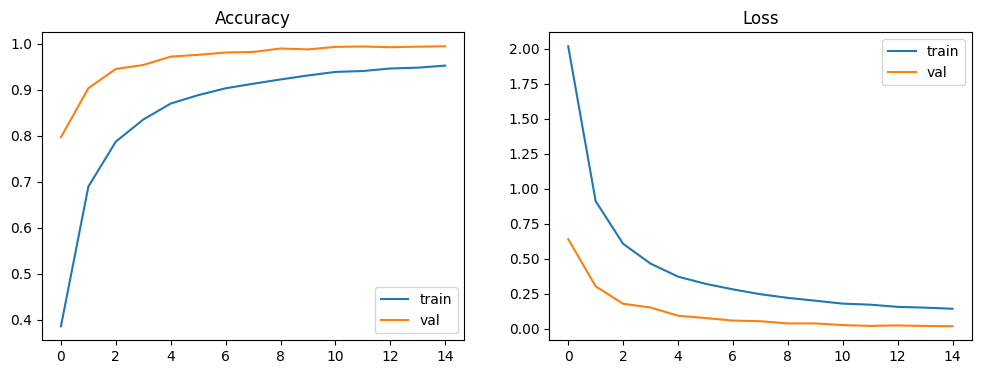

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       623
           B       0.99      1.00      0.99       634
           C       1.00      1.00      1.00       601
           D       1.00      1.00      1.00       643
           E       0.97      0.99      0.98       548
           F       1.00      1.00      1.00       646
           G       1.00      1.00      1.00       612
           H       1.00      1.00      1.00       626
           I       1.00      1.00      1.00       607
           J       1.00      1.00      1.00       626
           K       0.99      1.00      0.99       553
           L       1.00      1.00      1.00       593
           M       0.99      0.99      0.99       594
           N       0.99      0.99      0.99       555
           O       1.00      1.00      1.00       595
           P       1.00      1.00      1.00       606
           Q       0.99      1.00      1.00       636
           R       0.99    

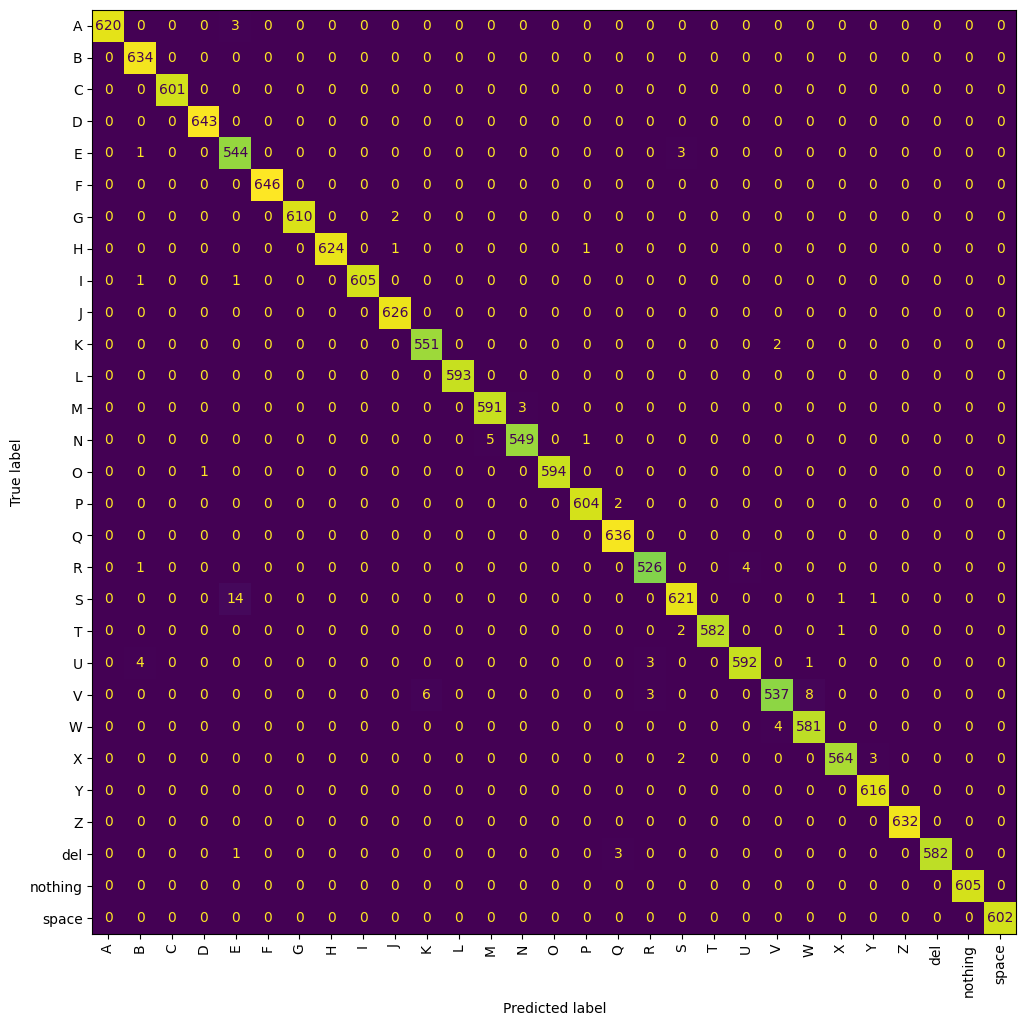

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true, y_pred = [], []
for x, y in val:
    p = model.predict(x, verbose=0)
    y_true += list(np.argmax(y.numpy(), axis=1))
    y_pred += list(np.argmax(p, axis=1))

print(classification_report(y_true, y_pred, target_names=classes))
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.show()

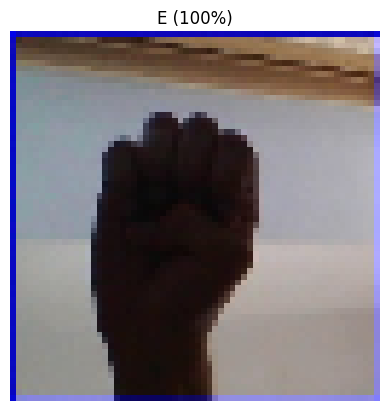

E: 100.0%
A: 0.0%
B: 0.0%


Saving WhatsApp Image 2026-10-24 at 16.34.48.jpeg to WhatsApp Image 2026-10-24 at 16.34.48.jpeg


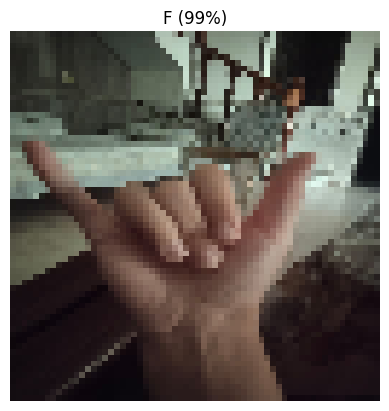

F: 98.9%
Y: 1.1%
W: 0.0%


In [ ]:
import numpy as np
def predict_image(p):
    img = tf.keras.utils.load_img(p, target_size=(IMG, IMG))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), 0)
    pred = model.predict(arr, verbose=0)[0]
    top = np.argsort(pred)[::-1][:3]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{classes[top[0]]} ({pred[top[0]]:.0%})"); plt.show()
    for i in top: print(f"{classes[i]}: {pred[i]:.1%}")

# dataset test image
predict_image(os.path.join(TEST, "E_test.jpg"))

# your own photo
from google.colab import files
up = files.upload()
predict_image(list(up.keys())[0])

In [ ]:
!pip install -q mediapipe
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

import cv2, os, random, numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1,
    min_hand_detection_confidence=0.3)
detector = vision.HandLandmarker.create_from_options(options)

def crop_hand(img_bgr, pad=0.25):
    h, w = img_bgr.shape[:2]
    rgb = np.ascontiguousarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.hand_landmarks:
        return None
    lm = res.hand_landmarks[0]
    xs = [p.x * w for p in lm]; ys = [p.y * h for p in lm]
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    side = max(max(xs) - min(xs), max(ys) - min(ys)) * (1 + 2 * pad)
    x1, x2 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, w))
    y1, y2 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, h))
    crop = img_bgr[y1:y2, x1:x2]
    return crop if crop.size else None

In [ ]:
import matplotlib.pyplot as plt
f = os.listdir(f"{TRAIN}/A")[0]
img = cv2.imread(f"{TRAIN}/A/{f}")
crop = crop_hand(img)
print("Detected" if crop is not None else "No hand found")
if crop is not None:
    plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

No hand found


In [ ]:
f = os.listdir(f"{TRAIN}/A")[0]
img = cv2.imread(f"{TRAIN}/A/{f}")
print(f, None if img is None else img.shape)

A2802.jpg (200, 200, 3)


In [ ]:
options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1,
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1)
detector = vision.HandLandmarker.create_from_options(options)

def crop_hand(img_bgr, pad=0.25):
    h, w = img_bgr.shape[:2]
    P = int(0.5 * max(h, w))                      # border on every side
    big = cv2.copyMakeBorder(img_bgr, P, P, P, P, cv2.BORDER_REPLICATE)
    bh, bw = big.shape[:2]
    s = 640 / max(bh, bw)                         # upscale for the detector
    big = cv2.resize(big, (int(bw * s), int(bh * s)))
    rgb = np.ascontiguousarray(cv2.cvtColor(big, cv2.COLOR_BGR2RGB))
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.hand_landmarks:
        return None
    lm = res.hand_landmarks[0]
    # convert landmarks back to original image coordinates
    xs = [p.x * bw - P for p in lm]
    ys = [p.y * bh - P for p in lm]
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    side = max(max(xs) - min(xs), max(ys) - min(ys)) * (1 + 2 * pad)
    x1, x2 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, w))
    y1, y2 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, h))
    crop = img_bgr[y1:y2, x1:x2]
    return crop if crop.size else None

In [ ]:
for letter in ["A", "B", "L", "M", "S"]:
    files = os.listdir(f"{TRAIN}/{letter}")[:30]
    ok = sum(crop_hand(cv2.imread(f"{TRAIN}/{letter}/{f}")) is not None for f in files)
    print(letter, f"{ok}/30 detected")

A 22/30 detected
B 26/30 detected
L 29/30 detected
M 20/30 detected
S 26/30 detected


In [ ]:
OUT, N, SIZE = "cropped", 1000, 128
random.seed(42)
for c in sorted(os.listdir(TRAIN)):
    os.makedirs(f"{OUT}/{c}", exist_ok=True)
    files = os.listdir(f"{TRAIN}/{c}")
    random.shuffle(files)
    saved = 0
    for f in files:
        if saved >= N: break
        img = cv2.imread(f"{TRAIN}/{c}/{f}")
        if img is None: continue
        crop = img if c == "nothing" else crop_hand(img)
        if crop is None: continue
        cv2.imwrite(f"{OUT}/{c}/{f}", cv2.resize(crop, (SIZE, SIZE)))
        saved += 1
    print(c, saved)

A 1000
B 1000
C 1000
D 1000
E 1000
F 1000
G 1000
H 1000
I 1000
J 1000
K 1000
L 1000
M 1000
N 1000
O 1000
P 1000
Q 1000
R 1000
S 1000
T 1000
U 1000
V 1000
W 1000
X 1000
Y 1000
Z 1000
del 1000
nothing 1000
space 1000


In [ ]:
!zip -rq cropped.zip cropped
from google.colab import files
files.download("cropped.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np, matplotlib.pyplot as plt

OUT, SIZE = "cropped", 128

train = tf.keras.utils.image_dataset_from_directory(
    OUT, validation_split=0.2, subset="training", seed=42,
    image_size=(SIZE, SIZE), batch_size=64, label_mode="categorical")
val = tf.keras.utils.image_dataset_from_directory(
    OUT, validation_split=0.2, subset="validation", seed=42,
    image_size=(SIZE, SIZE), batch_size=64, label_mode="categorical")

classes = train.class_names
print(classes)

train = train.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
val = val.cache().prefetch(tf.data.AUTOTUNE)

Found 29000 files belonging to 29 classes.
Using 23200 files for training.
Found 29000 files belonging to 29 classes.
Using 5800 files for validation.
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [ ]:
aug = models.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.3),
    layers.RandomContrast(0.3),
], name="augmentation")

base = tf.keras.applications.MobileNetV2(
    input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input((SIZE, SIZE, 3))
x = aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
model = models.Model(inputs, outputs)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
import os
print(os.path.exists("cropped"), os.path.exists("hand_landmarker.task"))

True True


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np, matplotlib.pyplot as plt

OUT, SIZE = "cropped", 128

train = tf.keras.utils.image_dataset_from_directory(
    OUT, validation_split=0.2, subset="training", seed=42,
    image_size=(SIZE, SIZE), batch_size=64, label_mode="categorical")
val = tf.keras.utils.image_dataset_from_directory(
    OUT, validation_split=0.2, subset="validation", seed=42,
    image_size=(SIZE, SIZE), batch_size=64, label_mode="categorical")
classes = train.class_names
print(classes)
train = train.cache().shuffle(1000).prefetch(tf.data.AUTOTUNE)
val = val.cache().prefetch(tf.data.AUTOTUNE)

aug = models.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.3),
    layers.RandomContrast(0.3),
], name="augmentation")

base = tf.keras.applications.MobileNetV2(
    input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = layers.Input((SIZE, SIZE, 3))
x = aug(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)
model = models.Model(inputs, outputs)

Found 29000 files belonging to 29 classes.
Using 23200 files for training.
Found 29000 files belonging to 29 classes.
Using 5800 files for validation.
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [ ]:
cb = [tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
      tf.keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2)]

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train, validation_data=val, epochs=8, callbacks=cb)

Epoch 1/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 49s 55ms/step - accuracy: 0.7004 - loss: 1.0080 - val_accuracy: 0.9362 - val_loss: 0.2035 - learning_rate: 0.0010
Epoch 2/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - accuracy: 0.8331 - loss: 0.5307 - val_accuracy: 0.9566 - val_loss: 0.1427 - learning_rate: 0.0010
Epoch 3/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.8572 - loss: 0.4499 - val_accuracy: 0.9540 - val_loss: 0.1393 - learning_rate: 0.0010
Epoch 4/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.8751 - loss: 0.3955 - val_accuracy: 0.9629 - val_loss: 0.1173 - learning_rate: 0.0010
Epoch 5/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.8794 - loss: 0.3676 - val_accuracy: 0.9584 - val_loss: 0.1260 - learning_rate: 0.0010
Epoch 6/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.8863 - loss: 0.3578 - val_accuracy: 0.9643 - val_loss: 0.1098 - learning_rate: 0.0010
Epoch 7/8
363/363 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.8878 - loss: 0.

In [ ]:
!unzip -q cropped.zip

replace cropped/R/R366.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os
for c in sorted(os.listdir("cropped")):
    print(c, len(os.listdir(f"cropped/{c}")), end=" | ")

A 1000 | B 1000 | C 1000 | D 1000 | E 1000 | F 1000 | G 1000 | H 1000 | I 1000 | J 1000 | K 1000 | L 1000 | M 1000 | N 1000 | O 1000 | P 1000 | Q 1000 | R 1000 | S 1000 | T 1000 | U 1000 | V 1000 | W 1000 | X 1000 | Y 1000 | Z 1000 | del 1000 | nothing 1000 | space 1000 | 

Training

In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
try:
    print("Phase 1 epochs done:", len(h1.history["accuracy"]))
    print("Last val accuracy:", h1.history["val_accuracy"][-1])
except NameError:
    print("h1 not found, Phase 1 results are gone")

Phase 1 epochs done: 8
Last val accuracy: 0.9703448414802551


In [ ]:
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train, validation_data=val, epochs=12, callbacks=cb)
model.save("phase2.keras")

Epoch 1/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.7736 - loss: 0.7693 - val_accuracy: 0.9581 - val_loss: 0.1376 - learning_rate: 1.0000e-05
Epoch 2/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.8448 - loss: 0.4966 - val_accuracy: 0.9598 - val_loss: 0.1242 - learning_rate: 1.0000e-05
Epoch 3/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.8767 - loss: 0.3914 - val_accuracy: 0.9676 - val_loss: 0.0999 - learning_rate: 1.0000e-05
Epoch 4/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.8972 - loss: 0.3266 - val_accuracy: 0.9700 - val_loss: 0.0915 - learning_rate: 1.0000e-05
Epoch 5/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.9112 - loss: 0.2754 - val_accuracy: 0.9743 - val_loss: 0.0791 - learning_rate: 1.0000e-05
Epoch 6/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.9203 - loss: 0.2449 - val_accuracy: 0.9774 - val_loss: 0.0687 - learning_rate: 1.0000e-05
Epoch 7/12
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/ste

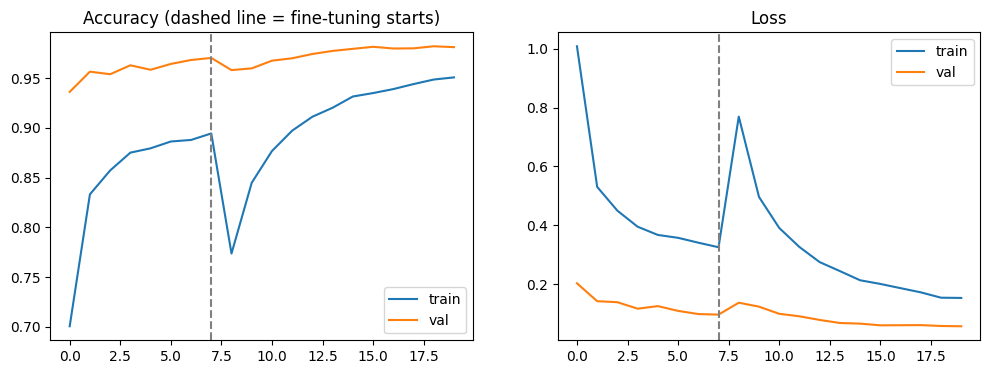

In [ ]:
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val")
ax[0].axvline(len(h1.history["accuracy"]) - 1, color="gray", linestyle="--")
ax[0].set_title("Accuracy (dashed line = fine-tuning starts)"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="val")
ax[1].axvline(len(h1.history["loss"]) - 1, color="gray", linestyle="--")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

              precision    recall  f1-score   support

           A       0.99      0.99      0.99       199
           B       0.99      1.00      1.00       201
           C       1.00      1.00      1.00       190
           D       1.00      0.96      0.98       189
           E       0.99      0.98      0.98       201
           F       1.00      1.00      1.00       209
           G       0.98      0.98      0.98       193
           H       0.99      0.99      0.99       183
           I       0.97      0.98      0.97       177
           J       0.99      0.98      0.98       179
           K       0.98      0.96      0.97       208
           L       1.00      0.99      0.99       215
           M       0.93      0.99      0.96       201
           N       0.99      0.93      0.96       198
           O       0.98      1.00      0.99       181
           P       0.98      1.00      0.99       192
           Q       1.00      0.97      0.99       193
           R       0.98    

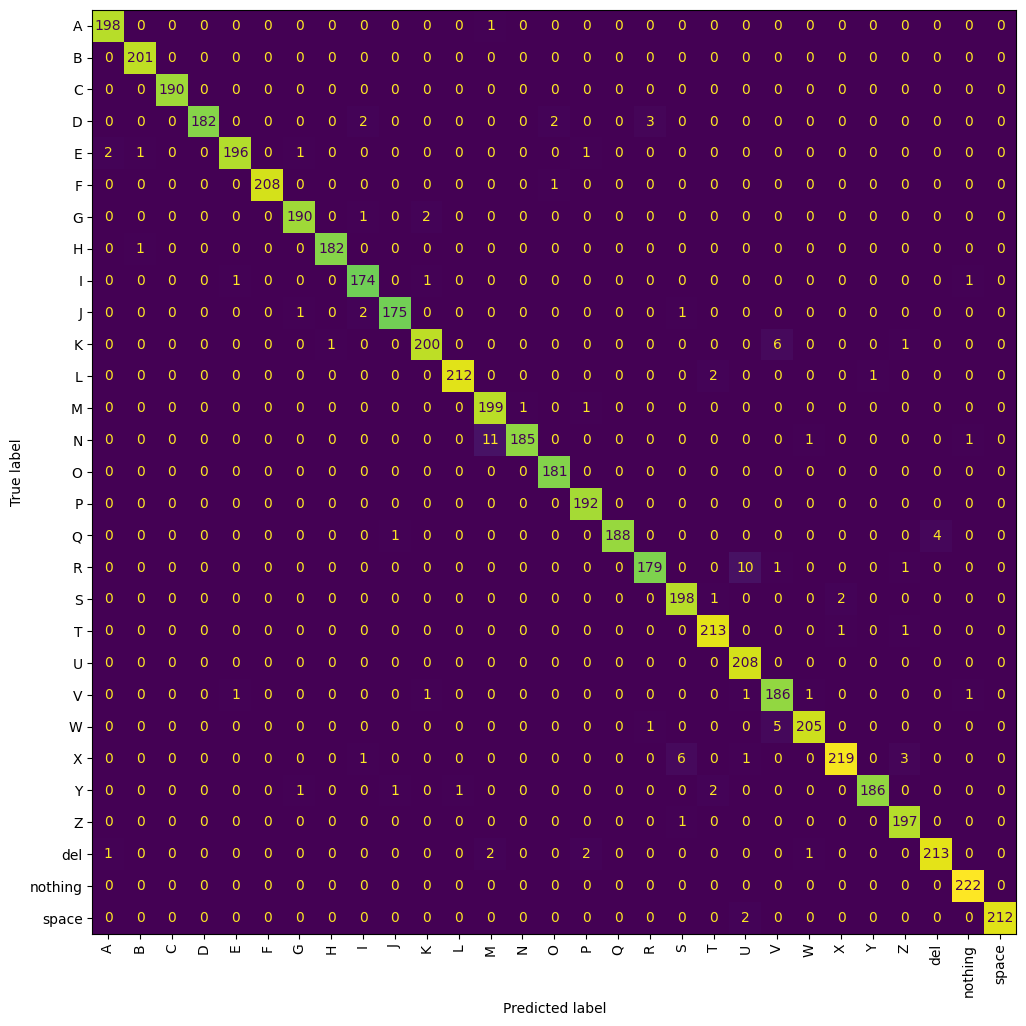

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

y_true, y_pred = [], []
for x, y in val:
    p = model.predict(x, verbose=0)
    y_true += list(np.argmax(y.numpy(), axis=1))
    y_pred += list(np.argmax(p, axis=1))

print(classification_report(y_true, y_pred, target_names=classes))
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(
    ax=ax, xticks_rotation=90, colorbar=False)
plt.show()

In [ ]:
import json
model.save("handtalk.keras")
json.dump(classes, open("classes.json", "w"))
from google.colab import files
files.download("handtalk.keras")
files.download("classes.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q mediapipe
import os
if not os.path.exists("hand_landmarker.task"):
    !wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

import cv2, numpy as np
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1,
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1)
detector = vision.HandLandmarker.create_from_options(options)

def crop_hand(img_bgr, pad=0.25):
    h, w = img_bgr.shape[:2]
    P = int(0.5 * max(h, w))
    big = cv2.copyMakeBorder(img_bgr, P, P, P, P, cv2.BORDER_REPLICATE)
    bh, bw = big.shape[:2]
    s = 640 / max(bh, bw)
    big = cv2.resize(big, (int(bw * s), int(bh * s)))
    rgb = np.ascontiguousarray(cv2.cvtColor(big, cv2.COLOR_BGR2RGB))
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.hand_landmarks:
        return None
    lm = res.hand_landmarks[0]
    xs = [p.x * bw - P for p in lm]
    ys = [p.y * bh - P for p in lm]
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    side = max(max(xs) - min(xs), max(ys) - min(ys)) * (1 + 2 * pad)
    x1, x2 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, w))
    y1, y2 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, h))
    crop = img_bgr[y1:y2, x1:x2]
    return crop if crop.size else None

In [ ]:
try:
    print(len(h1.history["accuracy"]), "Phase 1 epochs")
    print(len(h2.history["accuracy"]), "Phase 2 epochs")
    print("Last val accuracy:", h2.history["val_accuracy"][-1])
except NameError as e:
    print("Missing:", e)

8 Phase 1 epochs
12 Phase 2 epochs
Last val accuracy: 0.9812068939208984


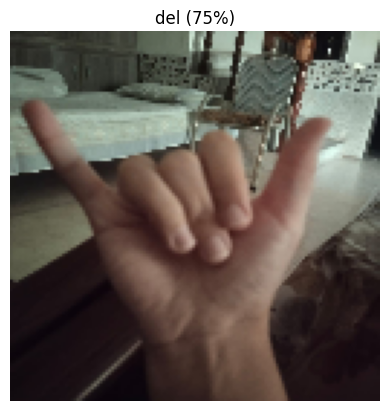

del: 75.0%
Y: 10.3%
N: 10.1%


In [ ]:
import matplotlib.pyplot as plt
SIZE = 128
predict_photo("WhatsApp Image 2026-10-24 at 16.34.48 (1).jpeg")

crop found: True


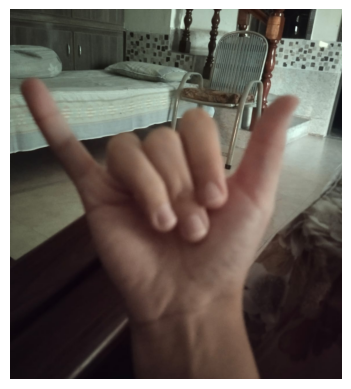

normal : [('del', '75%'), ('Y', '10%'), ('N', '10%')]
flipped: [('M', '40%'), ('N', '34%'), ('A', '7%')]


In [ ]:
img = cv2.imread("WhatsApp Image 2026-10-24 at 16.34.48 (1).jpeg")
crop = crop_hand(img)
print("crop found:", crop is not None)

def top3(rgb):
    p = model.predict(cv2.resize(rgb, (128,128))[None].astype("float32"), verbose=0)[0]
    return [(classes[i], f"{p[i]:.0%}") for i in np.argsort(p)[::-1][:3]]

if crop is not None:
    rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    plt.imshow(rgb); plt.axis("off"); plt.show()
    print("normal :", top3(rgb))
    print("flipped:", top3(cv2.flip(rgb, 1)))

In [ ]:
from google.colab import files
up = files.upload()            # name videos A.mp4, B.mp4, ... (use a few letters first to test)

def add_from_video(path, letter, every=3):
    cap = cv2.VideoCapture(path); i = saved = 0
    os.makedirs(f"cropped/{letter}", exist_ok=True)
    while True:
        ok, f = cap.read()
        if not ok: break
        if i % every == 0:
            c = crop_hand(f)
            if c is not None:
                cv2.imwrite(f"cropped/{letter}/own_{letter}_{saved}.jpg", cv2.resize(c, (128,128)))
                saved += 1
        i += 1
    print(letter, saved, "frames added")

for name in up:
    add_from_video(name, name.split(".")[0].upper())

Saving WhatsApp Image 2026-10-24 at 16.34.48.jpeg to WhatsApp Image 2026-10-24 at 16.34.48 (2).jpeg
WHATSAPP IMAGE 2026-10-24 AT 16 1 frames added


In [ ]:
!pip install -q mediapipe
import os
if not os.path.exists("hand_landmarker.task"):
    !wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

import cv2, numpy as np, random
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="hand_landmarker.task"),
    num_hands=1,
    min_hand_detection_confidence=0.1,
    min_hand_presence_confidence=0.1)
detector = vision.HandLandmarker.create_from_options(options)

print("cropped folder exists:", os.path.exists("cropped"))

cropped folder exists: False


In [ ]:
!unzip -qn cropped.zip
print(os.path.exists("cropped"))

unzip:  cannot find or open cropped.zip, cropped.zip.zip or cropped.zip.ZIP.
False


In [ ]:
import os, numpy as np, cv2, random
from mediapipe.tasks.python import vision

def get_landmarks(img_bgr):
    """Returns 63 normalized features or None if no hand found."""
    h, w = img_bgr.shape[:2]
    P = int(0.5 * max(h, w))
    big = cv2.copyMakeBorder(img_bgr, P, P, P, P, cv2.BORDER_REPLICATE)
    bh, bw = big.shape[:2]
    s = 640 / max(bh, bw)
    big = cv2.resize(big, (int(bw * s), int(bh * s)))
    rgb = np.ascontiguousarray(cv2.cvtColor(big, cv2.COLOR_BGR2RGB))
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.hand_landmarks:
        return None
    lm = res.hand_landmarks[0]
    pts = np.array([[p.x * bw, p.y * bh, p.z * bw] for p in lm], dtype="float32")
    return pts            # raw 21x3 points

def normalize(pts):
    pts = pts - pts[0]                              # wrist becomes origin
    scale = np.linalg.norm(pts[9]) + 1e-6           # wrist to middle knuckle
    return (pts / scale).flatten()                  # 63 numbers

X_raw, y = [], []
classes = sorted(c for c in os.listdir("cropped") if c != "nothing")
for ci, c in enumerate(classes):
    files = os.listdir(f"cropped/{c}")
    random.shuffle(files)
    n = 0
    for f in files:
        if n >= 700: break
        pts = get_landmarks(cv2.imread(f"cropped/{c}/{f}"))
        if pts is None: continue
        X_raw.append(pts); y.append(ci); n += 1
    print(c, n)

X_raw = np.array(X_raw); y = np.array(y)
np.savez("landmarks.npz", X=X_raw, y=y, classes=classes)

ModuleNotFoundError: No module named 'mediapipe'

In [ ]:
def augment(pts):
    p = pts.copy()
    a = np.radians(np.random.uniform(-20, 20))
    R = np.array([[np.cos(a), -np.sin(a), 0],
                  [np.sin(a),  np.cos(a), 0],
                  [0, 0, 1]], dtype="float32")
    p = p @ R.T                                   # small rotation
    p *= np.random.uniform(0.9, 1.1, size=(1, 3)) # small stretch
    p += np.random.normal(0, 0.01 * np.abs(p).max(), p.shape)  # jitter
    if np.random.rand() < 0.5:
        p[:, 0] = -p[:, 0] + 2 * p[0, 0]          # mirror: left/right hand
    return p

X, Y = [], []
for pts, lab in zip(X_raw, y):
    X.append(normalize(pts)); Y.append(lab)
    for _ in range(4):
        X.append(normalize(augment(pts))); Y.append(lab)
X, Y = np.array(X), np.array(Y)
print(X.shape)